&nbsp;

## [ENCODE-rE2G](https://github.com/EngreitzLab/ENCODE_rE2G) Result Parse Notebook

- [config_biosamples_hs_atacseq_hic_list.tsv](../../../out/ENCODE_rE2G/config/config_biosamples_hs_atacseq_hic_list.tsv)で定義した14個のデータセットでの enhancer-gene interaction の相互作用の結果をパースする notebook
- [ENCODE-rE2G](https://github.com/EngreitzLab/ENCODE_rE2G) での予測結果のうち、positive control となりそうな例について深堀りする

In [25]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [26]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261112


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## ENCODE-rE2G Filter Result (heat-stressed dataset)

- [02_encode_re2g_parse_hs.ipynb](../../05_ENCODE_rE2G/02_encode_re2g_parse_hs.ipynb) で解析したデータ

In [27]:
e2g_join = pl.read_parquet(
    "../../../out/ENCODE_rE2G/parquet_file/encode_re2g_hs_join_v261003.parquet"
).filter(
    pl.col("isSelfPromoter") == False
)

print(f"e2g_join count: {e2g_join.select(["cre_id", "target_cre_id"]).n_unique()}")
display(e2g_join)

e2g_join count: 368398


ENCODE-rE2G.Score,re2g_dataset,cre_id,cre_name,cre_chr,fantabio_cre_class,enhancer_cre_overlap_bp,enhancer_cre_overlap_frac_of_fantabio_cre,TargetGene,target_cre_id,target_cre_name,target_fantabio_cre_class,class,isSelfPromoter,distanceToTSS,re2g_enhancer_locus,fantabio_enhancer_cre,re2g_features,target_tss_info,target_cre_info,target_cre_overlap_info
f64,str,str,str,str,str,i64,f64,str,str,str,str,str,bool,f64,struct[3],struct[3],struct[8],struct[5],struct[10],struct[2]
0.342709,"""GSE154744_K562_42C_25min""","""FCHS_10001""","""FCHS_10001""","""chr1""","""ELA""",353,0.842482,"""AZIN2""","""FCHS_9997""","""cp4@AZIN2""","""ELA""","""genic""",false,15223.0,"{""chr1"",33097150,33097650}","{33097084,33097503,0.614679}","{33082177,""ENSG00000142920"",0.383964,null,0.044833,2,1,220.597881}","{""chr1"",33081927,33082427,0,""+""}","{""chr1"",33081878,33082317,0,""."",33081878,33082179,""255,202,74"",""directionality:1|class:ELA"",1.0}","{390,0.78}"
0.320048,"""GSE154744_K562_42C_60min""","""FCHS_10001""","""FCHS_10001""","""chr1""","""ELA""",288,0.687351,"""AZIN2""","""FCHS_9997""","""cp4@AZIN2""","""ELA""","""genic""",false,15288.0,"{""chr1"",33097215,33097715}","{33097084,33097503,0.614679}","{33082177,""ENSG00000142920"",0.402521,null,0.044762,4,1,253.0904}","{""chr1"",33081927,33082427,0,""+""}","{""chr1"",33081878,33082317,0,""."",33081878,33082179,""255,202,74"",""directionality:1|class:ELA"",1.0}","{390,0.78}"
0.312414,"""GSE267931_HUVEC_39C_120min""","""FCHS_10001""","""FCHS_10001""","""chr1""","""ELA""",358,0.854415,"""AZIN2""","""FCHS_9997""","""cp4@AZIN2""","""ELA""","""genic""",false,15218.0,"{""chr1"",33097145,33097645}","{33097084,33097503,0.614679}","{33082177,""ENSG00000142920"",0.466515,null,0.044839,4,1,506.041996}","{""chr1"",33081927,33082427,0,""+""}","{""chr1"",33081878,33082317,0,""."",33081878,33082179,""255,202,74"",""directionality:1|class:ELA"",1.0}","{390,0.78}"
0.194134,"""GSE267931_HUVEC_39C_120min""","""FCHS_10001""","""FCHS_10001""","""chr1""","""ELA""",358,0.854415,"""TRIM62""","""FCHS_10021""","""cp3@TRIM62""","""PLA""","""genic""",false,84675.0,"{""chr1"",33097145,33097645}","{33097084,33097503,0.614679}","{33182070,""ENSG00000116525"",0.524194,null,0.013442,13,1,506.041996}","{""chr1"",33181820,33182320,0,""-""}","{""chr1"",33181859,33182582,0,""."",33182047,33182188,""0,0,204"",""directionality:-0.999247|class:PLA"",-0.999247}","{461,0.922}"
0.291194,"""GSE173536_lymphblastoid_d21_42C_60min""","""FCHS_100026""","""FCHS_100026""","""chr12""","""ELA""",201,1.0,"""RASSF9""","""FCHS_100044""","""cp1@RASSF9""","""PLA""","""intergenic""",false,411922.0,"{""chr12"",85423911,85425325}","{85423957,85424158,0.5}","{85836540,""ENSG00000198774"",0.357834,null,0.00446,9,1,0.0}","{""chr12"",85836290,85836790,0,""-""}","{""chr12"",85836188,85836732,0,""."",85836213,85836732,""0,0,255"",""directionality:-1|class:PLA"",-1.0}","{442,0.884}"
0.282608,"""GSE173536_lymphblastoid_t21_42C_60min""","""FCHS_100026""","""FCHS_100026""","""chr12""","""ELA""",201,1.0,"""RASSF9""","""FCHS_100044""","""cp1@RASSF9""","""PLA""","""intergenic""",false,411926.5,"{""chr12"",85423907,85425320}","{85423957,85424158,0.5}","{85836540,""ENSG00000198774"",0.306494,null,0.00446,11,1,0.0}","{""chr12"",85836290,85836790,0,""-""}","{""chr12"",85836188,85836732,0,""."",85836213,85836732,""0,0,255"",""directionality:-1|class:PLA"",-1.0}","{442,0.884}"
0.275191,"""GSE105028_hESC_42C_60min""","""FCHS_100027""","""FCHS_100027""","""chr12""","""ELA""",127,1.0,"""KITLG""","""FCHS_100248""","""cp4@KITLG""","""PLA""","""intergenic""",false,3.111425e6,"{""chr12"",85468278,85469818}","{85468469,85468596,0.777778}","{88580473,""ENSG00000049130"",null,0.570841,0.012835,63,10,0.0}","{""chr12"",88580223,88580723,0,""-""}","{""chr12"",88580272,88580862,0,""."",88580470,88580561,""0,0,204"",""directionality:-0.863395|class:PLA"",-0.863395}","{451,0.902}"
0.819917,"""GSE105028_hESC_42C_60min""","""FCHS_100027""","""FCHS_100027""","""chr12""","""ELA""",127,1.0

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 7.  Enhancer-target Region Unique Count

- enhancer 側で統合した `fanta.bio` の `cre_id` と Target 側の領域として統合した `fanta.bio`の `target_cre_id` の unique pair をカウントする
- `re2g_dataset` カラムのカウントも行う

In [28]:
e2g_join_unique_count = e2g_join.group_by(
    "cre_id",
    "fantabio_cre_class",
    "target_cre_id",
    "target_fantabio_cre_class",
    # "isSelfPromoter" (この値は遺伝子ごとに異なるのでグループ化しない)
).agg(
    pl.col("re2g_dataset").unique().alias("re2g_dataset"),
    pl.col("re2g_dataset").n_unique().alias("re2g_dataset_count"),
    pl.col("ENCODE-rE2G.Score").alias("ENCODE-rE2G.Score"),
    
    pl.col("ENCODE-rE2G.Score").min().alias("ENCODE-rE2G.Score_min"),
    pl.col("ENCODE-rE2G.Score").max().alias("ENCODE-rE2G.Score_max"),
    pl.col("ENCODE-rE2G.Score").mean().alias("ENCODE-rE2G.Score_mean"),

    # pl.col("ENCODE-rE2G.Score").quantile(0.25).alias("ENCODE-rE2G.Score_q1"),
    # pl.col("ENCODE-rE2G.Score").median().alias("ENCODE-rE2G.Score_median"),
    # pl.col("ENCODE-rE2G.Score").quantile(0.75).alias("ENCODE-rE2G.Score_q3"),
    # pl.col("ENCODE-rE2G.Score").std().alias("ENCODE-rE2G.Score_std"),
    
).sort(
    by=["re2g_dataset_count"],
    descending=True
)


print(f"ENCODE-rE2G enhancer - target region interaction unique pair count: {e2g_join_unique_count.select(['cre_id', 'target_cre_id']).n_unique()}")
display(e2g_join_unique_count)

ENCODE-rE2G enhancer - target region interaction unique pair count: 368398


cre_id,fantabio_cre_class,target_cre_id,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,list[str],u32,list[f64],f64,f64,f64
"""FCHS_3646""","""PLA""","""FCHS_3650""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.565622, 0.445653, … 0.516016]",0.445653,0.863878,0.680015
"""FCHS_458460""","""ELA""","""FCHS_36134""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.697273, 0.768203, … 0.858738]",0.46902,0.914732,0.772373
"""FCHS_176435""","""ELA""","""FCHS_176438""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.600021, 0.647861, … 0.527903]",0.527903,0.859947,0.737539
"""FCHS_70901""","""ELA""","""FCHS_70905""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.800001, 0.861633, … 0.814011]",0.618214,0.986929,0.856531
"""FCHS_73535""","""PLA""","""FCHS_73518""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.659682, 0.678282, … 0.496324]",0.496324,0.818822,0.655213
"""FCHS_110926""","""PLA""","""FCHS_110981""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.514531, 0.414749, … 0.844052]",0.333292,0.939416,0.598498
"""FCHS_328787""","""PLA""","""FCHS_328782""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.210398, 0.227639, … 0.597007]",0.210398,0.877717,0.639725
"""FCHS_161941""","""ELA""","""FCHS_161946""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.862759, 0.954995, … 0.846479]",0.766048,0.975454,0.869473
"""FCHS_122635""","""ELA""","""FCHS_122629""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.720232, 0.47573, … 0.809127]",0.253173,0.906332,0.635583


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Specific Example [FCHS_571903](https://fanta.bio/cre/FCHS_571903) (Positive Control)

- [Stress-induced transcriptional memory accelerates promoter-proximal pause release and decelerates termination over mitotic divisions](https://doi.org/10.1016/j.molcel.2021.03.007) という論文 (この論文で作成されたATAC-seq などのデータセットを ENCODE-rE2G でも使用している) では、以下のような例が紹介されている
- [_TAX1BP1_](https://genenames.org/data/gene-symbol-report/#!/hgnc_id/HGNC:11575) の近傍のプロモーターには HSF1 は結合せず、その上流の 4.5kb 程度にある エンハンサーにHSF1が結合していることが報告されている
- この報告を positive control として使用できないか検証
- ゲノムブラウザーを見ながら、上流 のシスエレメント を見ていった
- 今のところ、[FCHS_571903](https://fanta.bio/cre/FCHS_571903)が最有力候補
- [FCHS_571900](https://fanta.bio/cre/FCHS_571900)も相互作用が予測されていることに注意

&nbsp;

&nbsp;

## (1) _TAX1BP1_ の メタ解析結果 確認

- `fanta.bio` との CRE 統合後の結果を確認
- 更に、ChIP-Atlas Diff Analysis による結果のフィルタリング後の結果とも確認

In [29]:
up5p_fantabio_cre = pl.read_parquet(
    "../../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
)

pl.Config.set_tbl_rows(2)
display(up5p_fantabio_cre)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A25289""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_400104""","""chr8""",27592922,"""27593122""","""FCHS_400104""","[""ENST00000774579.1""]","""0""",294,"[{""EH38E3824983"",""dELS""}]",null,"[{""HS_00105821"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""SVM""}, {""HS_00105822"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00105828"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}]",null,null,0.5,"""ELA""","""255,202,74""","""yellow"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (2) _TAX1BP1_ の 近傍のプロモーターを確認

- up5p transcripts に含まれている 転写産物が多かったため、MANE_select の tag がついている transcript を標的にした

In [30]:
TAX1BP1_up5p_cre = up5p_fantabio_cre.filter(
    pl.col("HGNC_ID") == "HGNC:11575"
).filter(
    pl.col("tags").list.contains("MANE_Select") # 一旦 MANE_Select のみをフィルタリング条件にする
)

pl.Config.set_tbl_rows(6)
print(TAX1BP1_up5p_cre.select("cre_id").unique())

pl.Config.set_tbl_rows(20)
display(TAX1BP1_up5p_cre)

shape: (3, 1)
┌─────────────┐
│ cre_id      │
│ ---         │
│ str         │
╞═════════════╡
│ FCHS_378089 │
│ FCHS_571905 │
│ FCHS_378090 │
└─────────────┘


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000396319.7""",95,20,291,75,66,14,171,52,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",5,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_571905""","""chr7""",27739448,"""27739821""","""cp6@TAX1BP1""","[""ENST00000422800.5""]","""0""",341,"[{""EH38E2543088"",""PLS""}, {""EH38E2543089"",""pELS""}]","[{""CTCF"",1757,[{""SRX12008350"",1757}, {""SRX12008355"",1249}, {""SRX13551281"",988}]}, {""TP63"",711,[{""SRX19885676"",711}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.860963,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000396319.7""",95,20,291,75,66,14,171,52,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",5,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",0,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null,0.997065,"""PLA""","""204,0,0""","""red"""
"""ENST00000396319.7""",95,20,291,75,66,14,171,52,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",5,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_378090""","""chr7""",27740368,"""27740731""","""cp7@TAX1BP1,cp2@TAX1BP1-AS1""","[""ENST00000441955.2"", ""ENST00000945749.1"", … ""NR_187572.1""]","""0""",-206,"[{""EH38E3764010"",""PLS""}, {""EH38E3764011"",""pELS""}]","[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX5874023"",961}, … {""SRX1514979"",894}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420573"",542}]}, … {""CHD8"",500,[{""SRX534844"",500}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_03039990"",""HepG2"",""Liver"",""Liver"",""High throughput""}]","[{""hg19::chr7:27780248..27780295,-;hg_83351.1"",""hg_83351.1""}]",null,-0.636364,"""ELA""","""255,202,74""","""yellow"""


&nbsp;

&nbsp;

&nbsp;

## (3) Diff analysis (ATAC-seq) で確認

- この近傍の CRE が、Diff Analysis でヒットしているかどうかを確認

In [31]:
# After Diff Analysis
up5p_cre_diff_analysis = pl.read_parquet(
    "../../../out/ChIP-Atlas_diff/diff_analysis_filter_parquet/transcript_cre/fantabio_HN2_up5p_v261002_diff_analysis_atac.parquet"
)

TAX1BP1_up5p_cre_diff_analysis = up5p_cre_diff_analysis.filter(
    pl.col("HGNC_ID") == "HGNC:11575"
).filter(
    pl.col("cre_id").is_in(TAX1BP1_up5p_cre["cre_id"].implode())
)

pl.Config.set_tbl_rows(6)
display(TAX1BP1_up5p_cre_diff_analysis)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,cre_start,cre_end,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,i64,i64,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]
"""ENST00000916540.1""",144,27,235,117,74,10,167,64,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""TAGENE""]","""+""",2,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""LRGASP""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",0,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null,0.997065,"""PLA""","""204,0,0""","""red""",27739898,27740358,[0.254348],"[{27740194,27740311,""chr7""}]",[1.880554],[2.9054e-8],[0.000001],"[""GSE101731_atac_hff_44C_120min""]",1,"[""GSE101731_atac_hff_44C_120min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]"
"""ENST00000422800.5""",131,44,231,87,78,21,152,57,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""alternative_5_UTR"", ""mRNA_end_NF"", ""cds_end_NF""]","""+""",3,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""alternative 5' UTR""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",-297,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null,0.997065,"""PLA""","""204,0,0""","""red""",27739898,27740358,[0.254348],"[{27740194,27740311,""chr7""}]",[1.880554],[2.9054e-8],[0.000001],"[""GSE101731_atac_hff_44C_120min""]",1,"[""GSE101731_atac_hff_44C_120min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]"
"""ENST00000945738.1""",148,70,188,78,99,35,117,64,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""TAGENE""]","""+""",2,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""ENCODE_tissue""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",0,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {"

In [32]:
TAX1BP1_proximal_cre_list = [
    "FCHS_378089",
    "FCHS_378090",
    "FCHS_571905"
]

&nbsp;

&nbsp;

&nbsp;

## (4) Diff Analysis (ChIP-seq; HSF1) で check

- HSF1 の結合ポテンシャルがないか調べる

In [33]:
diff_analysis_hs_hsf1 = pl.read_parquet(
    "../../../out/ChIP-Atlas_diff/diff_analysis_filter_parquet/only_cre/fantabio_cre_list_diff_analysis_chipseq_hsf1.parquet"
)

is_hsf1_hit = diff_analysis_hs_hsf1.filter(
    pl.col("cre_id").is_in(TAX1BP1_proximal_cre_list)
)

display(is_hsf1_hit)

cre_chrom,cre_start,cre_end,cre_id,cre_name,directionality,fantabio_cre_class,motif_hit,n_motif_hit,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,str,str,f64,str,list[struct[9]],u32,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]


In [34]:
# Motif 解析の結果だけからも調べる
fimo_result = pl.read_csv(
    "../../../out/fantabio/HSF1_motif/HSF1_MA0486_cre_peaks_fimo/fimo.tsv",
    separator="\t",
    comment_prefix="#"
).filter(
    pl.col("sequence_name").is_in(TAX1BP1_proximal_cre_list)
)

display(fimo_result)

motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence
str,str,str,i64,i64,str,f64,f64,f64,str
"""MA0486.1""","""HSF1""","""FCHS_571905""",309,323,"""+""",9.88732,0.0000775,0.52,"""TCTCTGGCTATTTCC"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (5) _TAX1BP1_ の 近傍の CRE の metadata check

- HSF1 が結合するポテンシャルがあるかチェック

In [35]:
# 近傍に Ensembl transcript ID があるかどうかはフィルタリング条件には使用していない
fantabio_cre_human_metadata = pl.read_ndjson(
    "../../../Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks_annotation.jsonl.gz"
).drop(
    "cre_old_names",
    "tss_ncbi_geneids",
    "tss_hgnc_mgi_ids",
    "tss_uniprot_ids",
    "tss_gene_names",
    "tss_gene_symbols",
    "tss_gene_synonyms",
    "tss_gene_sources"
).with_columns(
    # Q-score は後々フィルタリングの条件に使うかもしれないため、cast(pl.Int64) で整数型に変換しておく
    # print(fanta_bio_human_metadata["chip_atlas_antigens"].dtype) で確認できる
    pl.col("chip_atlas_antigens").list.eval(
        pl.struct([
            pl.element().struct.field("antigen").alias("antigen"),
            pl.element().struct.field("maxqscore").cast(pl.Int64).alias("maxqscore"),
            pl.element().struct.field("experiments").list.eval(
                pl.struct([
                    pl.element().struct.field("id").alias("id"),
                    pl.element().struct.field("qscore").cast(pl.Int64).alias("qscore"),
                ])
            ).alias("experiments"),
        ])
    ).alias("chip_atlas_antigens"),
)

pl.Config.set_tbl_rows(2)
print(fantabio_cre_human_metadata.select("cre_id").n_unique())
display(fantabio_cre_human_metadata)

513895


cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]]
"""FCHS_1""","""chr1""",10610,"""10687""","""cp1@DDX11L1""","[""ENST00000832824.1""]","""434""","[{""ENST00000832824.1"",""434""}, {""ENST00000832825.1"",""438""}]","[{""EH38E2776517"",""pELS""}]","[{""EGR1"",2552,[{""SRX22828712"",2552}, {""SRX22828708"",1544}, {""SRX22828709"",1187}]}, {""BRD3"",1874,[{""SRX366792"",1874}, {""SRX366793"",621}, {""SRX366794"",537}]}, … {""NRF1"",807,[{""SRX2636389"",807}, {""SRX23881992"",770}, {""SRX1280449"",580}]}]",null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_593940""","""chrY""",56881615,"""56881922""","""FCHS_593940""","[""ENST00000810723.1""]","""0""","[{""ENST00000810723.1"",""0""}]",null,"[{""RELA"",1452,[{""SRX5938177"",1452}]}, {""RNF2"",939,[{""SRX18954702"",939}, {""SRX18954704"",699}]}, … {""DLX5"",504,[{""SRX17306262"",504}]}]",null,"[{""hg19::chrY:59027988..59028000,+;hg_201233.1"",""hg_201233.1""}]",null


In [36]:
TAX1BP1_proximal_cre = fantabio_cre_human_metadata.filter(
    pl.col("cre_id").is_in(TAX1BP1_proximal_cre_list)
)

pl.Config.set_tbl_rows(6)
display(TAX1BP1_proximal_cre)

cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]]
"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""","[{""ENST00000806472.1"",""0""}, {""ENST00000806474.1"",""0""}, … {""NR_187572.1"",""-317""}]","[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null
"""FCHS_378090""","""chr7""",27740368,"""27740731""","""cp7@TAX1BP1,cp2@TAX1BP1-AS1""","[""ENST00000441955.2"", ""ENST00000945749.1"", … ""NR_187572.1""]","""0""","[{""ENST00000441955.2"",""0""}, {""ENST00000945749.1"",""0""}, … {""MA619688"",""-273""}]","[{""EH38E3764010"",""PLS""}, {""EH38E3764011"",""pELS""}]","[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX5874023"",961}, … {""SRX1514979"",894}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420573"",542}]}, … {""CHD8"",500,[{""SRX534844"",500}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_03039990"",""HepG2"",""Liver"",""Liver"",""High throughput""}]","[{""hg19::chr7:27780248..27780295,-;hg_83351.1"",""hg_83351.1""}]",null
"""FCHS_571905""","""chr7""",27739448,"""27739821""","""cp6@TAX1BP1""","[""ENST00000422800.5""]","""0""","[{""ENST00000422800.5"",""0""}, {""ENST00000543117.5"",""-75""}, … {""BC050358"",""389""}]","[{""EH38E2543088"",""PLS""}, {""EH38E2543089"",""pELS""}]","[{""CTCF"",1757,[{""SRX12008350"",1757}, {""SRX12008355"",1249}, {""SRX13551281"",988}]}, {""TP63"",711,[{""SRX19885676"",711}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null


&nbsp;

&nbsp;

## (5) CHECK HSF1 Binding Poteintial (from `fanta.bio` information)

- TAX1BP1 の近傍の シスエレメントには、Heat Shock Factor 1 (HSF1) の結合ポテンシャルがないことを `fanta.bio`の JSON metadata から簡単にチェックする

In [37]:
# True if any nested antigen name equals HSF1; null antigen lists become False
TAX1BP1_proximal_cre = TAX1BP1_proximal_cre.with_columns(
    pl.when(
        pl.col("chip_atlas_antigens")
        .list.eval(pl.element().struct.field("antigen") == "HSF1")
        .list.any()
        .fill_null(False)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("has_HSF1"),
)

pl.Config.set_tbl_rows(6)
display(
    TAX1BP1_proximal_cre.select(
        "cre_id",
        "cre_name",
        "has_HSF1",
        "chip_atlas_antigens",
    )
)

cre_id,cre_name,has_HSF1,chip_atlas_antigens
str,str,bool,list[struct[3]]
"""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""",false,"[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]"
"""FCHS_378090""","""cp7@TAX1BP1,cp2@TAX1BP1-AS1""",false,"[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX5874023"",961}, … {""SRX1514979"",894}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420573"",542}]}, … {""CHD8"",500,[{""SRX534844"",500}]}]"
"""FCHS_571905""","""cp6@TAX1BP1""",false,"[{""CTCF"",1757,[{""SRX12008350"",1757}, {""SRX12008355"",1249}, {""SRX13551281"",988}]}, {""TP63"",711,[{""SRX19885676"",711}]}]"


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (4) Upstream Enhancer

- [Stress-induced transcriptional memory accelerates promoter-proximal pause release and decelerates termination over mitotic divisions](https://doi.org/10.1016/j.molcel.2021.03.007) という論文 (この論文で作成されたATAC-seq などのデータセットを ENCODE-rE2G でも使用している) では、以下のような例が紹介されている
- [_TAX1BP1_](https://genenames.org/data/gene-symbol-report/#!/hgnc_id/HGNC:11575) の近傍のプロモーターには HSF1 は結合せず、その上流の 4.5kb 程度にある エンハンサーにHSF1が結合していることが報告されている
- この報告を positive control として使用できないか検証
- ゲノムブラウザーを見ながら、上流 のシスエレメント を見ていった
- 今のところ、[FCHS_571903](https://fanta.bio/cre/FCHS_571903)が最有力候補
- [FCHS_571900](https://fanta.bio/cre/FCHS_571900)も相互作用が予測されていることを確認

&nbsp;

### 確認済み

- FCHS_378085
- FCHS_571902
- FCHS_571901

In [38]:
#check candidate no.1
# SCREEN Overlapped CRE: EH38E3764005: https://screen.wenglab.org/GRCh38/ccre/EH38E3764005
FCHS_571903 = e2g_join.filter(
    pl.col("cre_id") == "FCHS_571903"
)

FCHS_571903_metadata = fantabio_cre_human_metadata.filter(
    pl.col("cre_id") == "FCHS_571903"
).with_columns(
    pl.when(
        pl.col("chip_atlas_antigens")
        .list.eval(pl.element().struct.field("antigen") == "HSF1")
        .list.any()
        .fill_null(False)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("has_HSF1"),
)

FCHS_571903_e2g_join_unique_count = e2g_join_unique_count.filter(
    pl.col("cre_id") == "FCHS_571903"
)

pl.Config.set_tbl_rows(14)
display(FCHS_571903_metadata)
display(FCHS_571903_e2g_join_unique_count)
display(FCHS_571903)

cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,has_HSF1
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],bool
"""FCHS_571903""","""chr7""",27734628,"""27734903""","""FCHS_571903""",[],null,[],"[{""EH38E3764005"",""dELS""}]","[{""HSF1"",3486,[{""SRX16646095"",3486}, {""SRX16646111"",3316}, … {""SRX690824"",578}]}, {""SUMO2"",1912,[{""SRX895420"",1912}, {""SRX895419"",1713}]}, … {""STAT3"",560,[{""SRX347427"",560}]}]","[{""HS_01187824"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""gkmSVM""}, {""HS_01187825"",""Transverse Colon"",""Colon"",""Intestine"",""gkmSVM""}, … {""HS_01187828"",""Transverse Colon"",""Colon"",""Intestine"",""gkmSVM""}]",null,"[{[""chr7:27734627-27734902""]}]",true


cre_id,fantabio_cre_class,target_cre_id,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,list[str],u32,list[f64],f64,f64,f64
"""FCHS_571903""","""ELA""","""FCHS_378089""","""PLA""","[""GSE154744_K562_42C_25min"", ""GSE154744_K562_42C_30min"", … ""GSE280307_THP1_42C_120min""]",8,"[0.396576, 0.291939, … 0.625849]",0.281288,0.625849,0.396492


ENCODE-rE2G.Score,re2g_dataset,cre_id,cre_name,cre_chr,fantabio_cre_class,enhancer_cre_overlap_bp,enhancer_cre_overlap_frac_of_fantabio_cre,TargetGene,target_cre_id,target_cre_name,target_fantabio_cre_class,class,isSelfPromoter,distanceToTSS,re2g_enhancer_locus,fantabio_enhancer_cre,re2g_features,target_tss_info,target_cre_info,target_cre_overlap_info
f64,str,str,str,str,str,i64,f64,str,str,str,str,str,bool,f64,struct[3],struct[3],struct[8],struct[5],struct[10],struct[2]
0.396576,"""GSE154744_K562_42C_25min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",238,0.862319,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5479.0,"{""chr7"",27734365,27734865}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.900731,null,0.084905,1,1,1195.559684}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.291939,"""GSE154744_K562_42C_30min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5402.0,"{""chr7"",27734442,27734942}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.902908,null,0.085683,1,1,1061.389686}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.281288,"""GSE154744_K562_42C_30min_intact_hic""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5402.0,"{""chr7"",27734442,27734942}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.902908,null,0.105664,1,1,1061.389686}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.463824,"""GSE154744_K562_42C_40min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5381.0,"{""chr7"",27734463,27734963}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.896037,null,0.085899,1,1,1190.816587}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.417098,"""GSE154744_K562_42C_60min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5316.0,"{""chr7"",27734528,27735028}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.89069,null,0.08658,1,1,1108.905887}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.406878,"""GSE209675_MCF7_42C_60min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5261.0,"{""chr7"",27734583,27735083}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.876028,null,0.08717,2,1,824.69485}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.288484,"""GSE267931_HUVEC_39C_120min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5340.5,"{""chr7"",27734381,27735126}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.945998,null,0.086321,1,1,1000.391399}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0

In [39]:
# check candidate no.5
FCHS_571900 = e2g_join.filter(
    pl.col("cre_id") == "FCHS_571900"
)

FCHS_571900_metadata = fantabio_cre_human_metadata.filter(
    pl.col("cre_id") == "FCHS_571900"
).with_columns(
    pl.when(
        pl.col("chip_atlas_antigens")
        .list.eval(pl.element().struct.field("antigen") == "HSF1")
        .list.any()
        .fill_null(False)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("has_HSF1"),
)

pl.Config.set_tbl_rows(14)
display(FCHS_571900_metadata)
display(FCHS_571900)

cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,has_HSF1
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],bool
"""FCHS_571900""","""chr7""",27693864,"""27694045""","""FCHS_571900""",[],null,[],"[{""EH38E3763988"",""dELS""}]","[{""HLF"",2506,[{""SRX4572976"",2506}, {""SRX2636012"",2336}, {""SRX2636013"",2235}]}, {""NFIL3"",2037,[{""SRX2630334"",2037}, {""SRX2630333"",1446}]}, … {""MYC"",527,[{""SRX150722"",527}]}]","[{""HS_00089021"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, {""HS_01187752"",""Fetal Brain Female"",""Brain"",""Brain"",""gkmSVM""}, … {""HS_03200221"",""Fetal Muscle Trunk"",""Muscle"",""Muscle"",""DeepSilencer""}]",null,null,false


ENCODE-rE2G.Score,re2g_dataset,cre_id,cre_name,cre_chr,fantabio_cre_class,enhancer_cre_overlap_bp,enhancer_cre_overlap_frac_of_fantabio_cre,TargetGene,target_cre_id,target_cre_name,target_fantabio_cre_class,class,isSelfPromoter,distanceToTSS,re2g_enhancer_locus,fantabio_enhancer_cre,re2g_features,target_tss_info,target_cre_info,target_cre_overlap_info
f64,str,str,str,str,str,i64,f64,str,str,str,str,str,bool,f64,struct[3],struct[3],struct[8],struct[5],struct[10],struct[2]
0.375959,"""GSE154744_K562_42C_30min_intact_hic""","""FCHS_571900""","""FCHS_571900""","""chr7""","""ELA""",182,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,46100.0,"{""chr7"",27693744,27694244}","{27693863,27694045,-0.906977}","{27740094,""ENSG00000106052"",0.902908,null,0.068941,8,1,49.39023}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## enhancer が Diff Analysis (ATAC-seq; ChIP-seq) で検出されているか

In [40]:
atac_only_cre = pl.read_parquet(
    "../../../out/ChIP-Atlas_diff/diff_analysis_filter_parquet/only_cre/fantabio_cre_list_diff_analysis_atac.parquet"
)

is_atac_hit_enhancer = atac_only_cre.filter(
    pl.col("cre_id").is_in(FCHS_571903_e2g_join_unique_count["cre_id"].implode())
)

display(is_atac_hit_enhancer)

cre_chrom,cre_start,cre_end,cre_id,cre_name,directionality,fantabio_cre_class,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,str,str,f64,str,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]


In [41]:
is_hsf1_hit_enhancer = diff_analysis_hs_hsf1.filter(
    pl.col("cre_id").is_in(FCHS_571903_e2g_join_unique_count["cre_id"].implode())
)

display(is_hsf1_hit_enhancer)

cre_chrom,cre_start,cre_end,cre_id,cre_name,directionality,fantabio_cre_class,motif_hit,n_motif_hit,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,str,str,f64,str,list[struct[9]],u32,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]
"""chr7""",27734627,27734903,"""FCHS_571903""","""FCHS_571903""",0.375,"""ELA""","[{""MA0486.1"",""HSF1"",157,171,""-"",16.8028,9.5000e-7,0.147,""TTTCTAGCAAGTTCC""}, {""MA0486.1"",""HSF1"",107,121,""-"",16.2817,0.000002,0.178,""TTTCTGGCAAGTTCC""}, … {""MA0486.2"",""HSF1"",133,145,""-"",5.54839,0.0000998,0.963,""GTCTAGCAAGTTC""}]",17,"[0.949275, 0.818841, 1.0]","[{27734641,27734916,""chr7""}, {27734635,27734861,""chr7""}, {27734554,27735017,""chr7""}]","[3.478373, 3.46881, 2.744372]","[4.9206e-9, 6.5977e-12, 1.9431e-8]","[1.3487e-7, 5.5352e-10, 2.5242e-7]","[""pair1_GSE38901_hsf1_mcf10a_hs_42C_60min"", ""pair2_GSE43579_hsf1_k562_hs_42C_30min"", ""pair6_GSE209667_hsf1_polyclonal_ab_hs_42C_60min""]",3,"[""pair1_GSE38901_hsf1_mcf10a_hs_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed"", ""pair2_GSE43579_hsf1_k562_hs_42C_30min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed"", ""pair6_GSE209667_hsf1_polyclonal_ab_hs_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]"


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (5) Visualization

- `pyGenometracks` で可視化

In [42]:
# Plot window: UCSC chr7:27,727,278-27,742,181 (TAX1BP1 locus)
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&lastVirtModeType=default&lastVirtModeExtraState=&virtModeType=default&virtMode=0&nonVirtPosition=&position=chr7%3A27727278%2D27742181&hgsid=4186828185_2DeoykeVyrN4RTEy7WW2ufDPhfJ3

REGION_CHROM = "chr7"
REGION_START = 27_727_278
REGION_END = 27_742_181

repo_root = pathlib.Path("../../../").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/transcript_survey/pygenometracks"
    / f"FCHS_571903_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

region_bed = out_dir / "region.bed"
gtf_window = out_dir / "gencode.v49.window.gtf"
region_bed.write_text(f"{REGION_CHROM}\t{REGION_START}\t{REGION_END}\n")
print(out_dir)

/workspaces/HS_human_ncRNA/out/transcript_survey/pygenometracks/FCHS_571903_chr7_27727278_27742181


In [43]:
# Enhancer-promoter arcs from FCHS_571903_e2g_join_unique_count (one arc per CRE pair).
ep_pairs = FCHS_571903_e2g_join_unique_count.select(
    "cre_id", "target_cre_id", "ENCODE-rE2G.Score_mean"
).unique(subset=["cre_id", "target_cre_id"], maintain_order=True)

cre_ids = pl.concat(
    [
        ep_pairs.select("cre_id"),
        ep_pairs.select(pl.col("target_cre_id").alias("cre_id")),
    ]
).unique(maintain_order=True)

# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

fchs_cre_bed9 = out_dir / "FCHS_571903_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_id", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(fchs_cre_bed9, separator="\t", include_header=False)

coords = cre_keep.select("cre_id", "chrom", "start", "end")
links = (
    ep_pairs.join(
        coords.rename({"chrom": "chrom1", "start": "start1", "end": "end1"}),
        on="cre_id",
        how="inner",
    ).join(
        coords.rename(
            {
                "cre_id": "target_cre_id",
                "chrom": "chrom2",
                "start": "start2",
                "end": "end2",
            }
        ),
        on="target_cre_id",
        how="inner",
    )
).select(
    "chrom1", "start1", "end1", "chrom2", "start2", "end2",
    pl.col("ENCODE-rE2G.Score_mean"),
)
fchs_links = out_dir / "FCHS_571903_re2g.links"
links.write_csv(fchs_links, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
print(f"arcs: {links.height}")
display(links)

CRE intervals: 2
arcs: 1


chrom1,start1,end1,chrom2,start2,end2,ENCODE-rE2G.Score_mean
str,i64,i64,str,i64,i64,f64
"""chr7""",27734627,27734903,"""chr7""",27739898,27740358,0.396492


In [44]:
# Cut the GTF to the window, then keep only up5p_fantabio_cre transcripts.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
gtf_hits = subprocess.run(
    ["bedtools", "intersect", "-a", str(gtf_full), "-b", str(region_bed), "-wa"],
    check=True,
    capture_output=True,
    text=True,
)
gtf_window.write_text(gtf_header.stdout + gtf_hits.stdout)

up5p_tx_set = set(up5p_fantabio_cre["transcript_id"].unique().to_list())
fchs_gtf = out_dir / "FCHS_571903_up5p_transcripts.gtf"
gtf_lines = []
tx_in_window = set()
for line in gtf_window.read_text().splitlines():
    if line.startswith("#"):
        gtf_lines.append(line)
        continue
    match = re.search(r'transcript_id "([^"]+)"', line)
    if match and match.group(1) in up5p_tx_set:
        gtf_lines.append(line)
        tx_in_window.add(match.group(1))
fchs_gtf.write_text("\n".join(gtf_lines) + "\n")

# A gtf track has one color, so convert to BED12 with itemRgb per strand (UCSC-like).
# sense = TAX1BP1 strand (+) in dark blue, antisense in dark green.
from pygenometracks.readGtf import ReadGtf

SENSE_STRAND = "+"
SENSE_RGB = "0,0,139"
ANTISENSE_RGB = "0,100,0"
# BED12 blocks must span the whole transcript, so pull full models (not window-clipped lines).
fchs_gtf_full = out_dir / "FCHS_571903_up5p_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_in_window))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
fchs_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

fchs_bed12 = out_dir / "FCHS_571903_up5p_transcripts.bed12.bed"
with fchs_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(fchs_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        rgb = SENSE_RGB if tx.strand == SENSE_STRAND else ANTISENSE_RGB
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, tx.name, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, rgb, tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"up5p transcripts in window: {len(tx_in_window)}")
pl.Config.set_tbl_rows(20)
display(
    up5p_fantabio_cre.filter(pl.col("transcript_id").is_in(list(tx_in_window)))
    .select("transcript_id", "gene_symbol", "transcript_type", "strand")
    .unique()
    .sort("gene_symbol", "transcript_id")
)

up5p transcripts in window: 7


transcript_id,gene_symbol,transcript_type,strand
str,str,str,str
"""ENST00000396319.7""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000422800.5""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000871702.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000871717.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000916540.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000945738.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000441955.2""","""TAX1BP1-AS1""","""lncRNA""","""-"""


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 1/1 [00:00<00:00, 18808.54it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 2/2 [00:00<00:00, 36002.61it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [up5p transcripts]
100%|██████████| 7/7 [00:00<00:00, 46382.51it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.007663726806640625
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 10.904255319148938. Dpi is set to 300

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.track

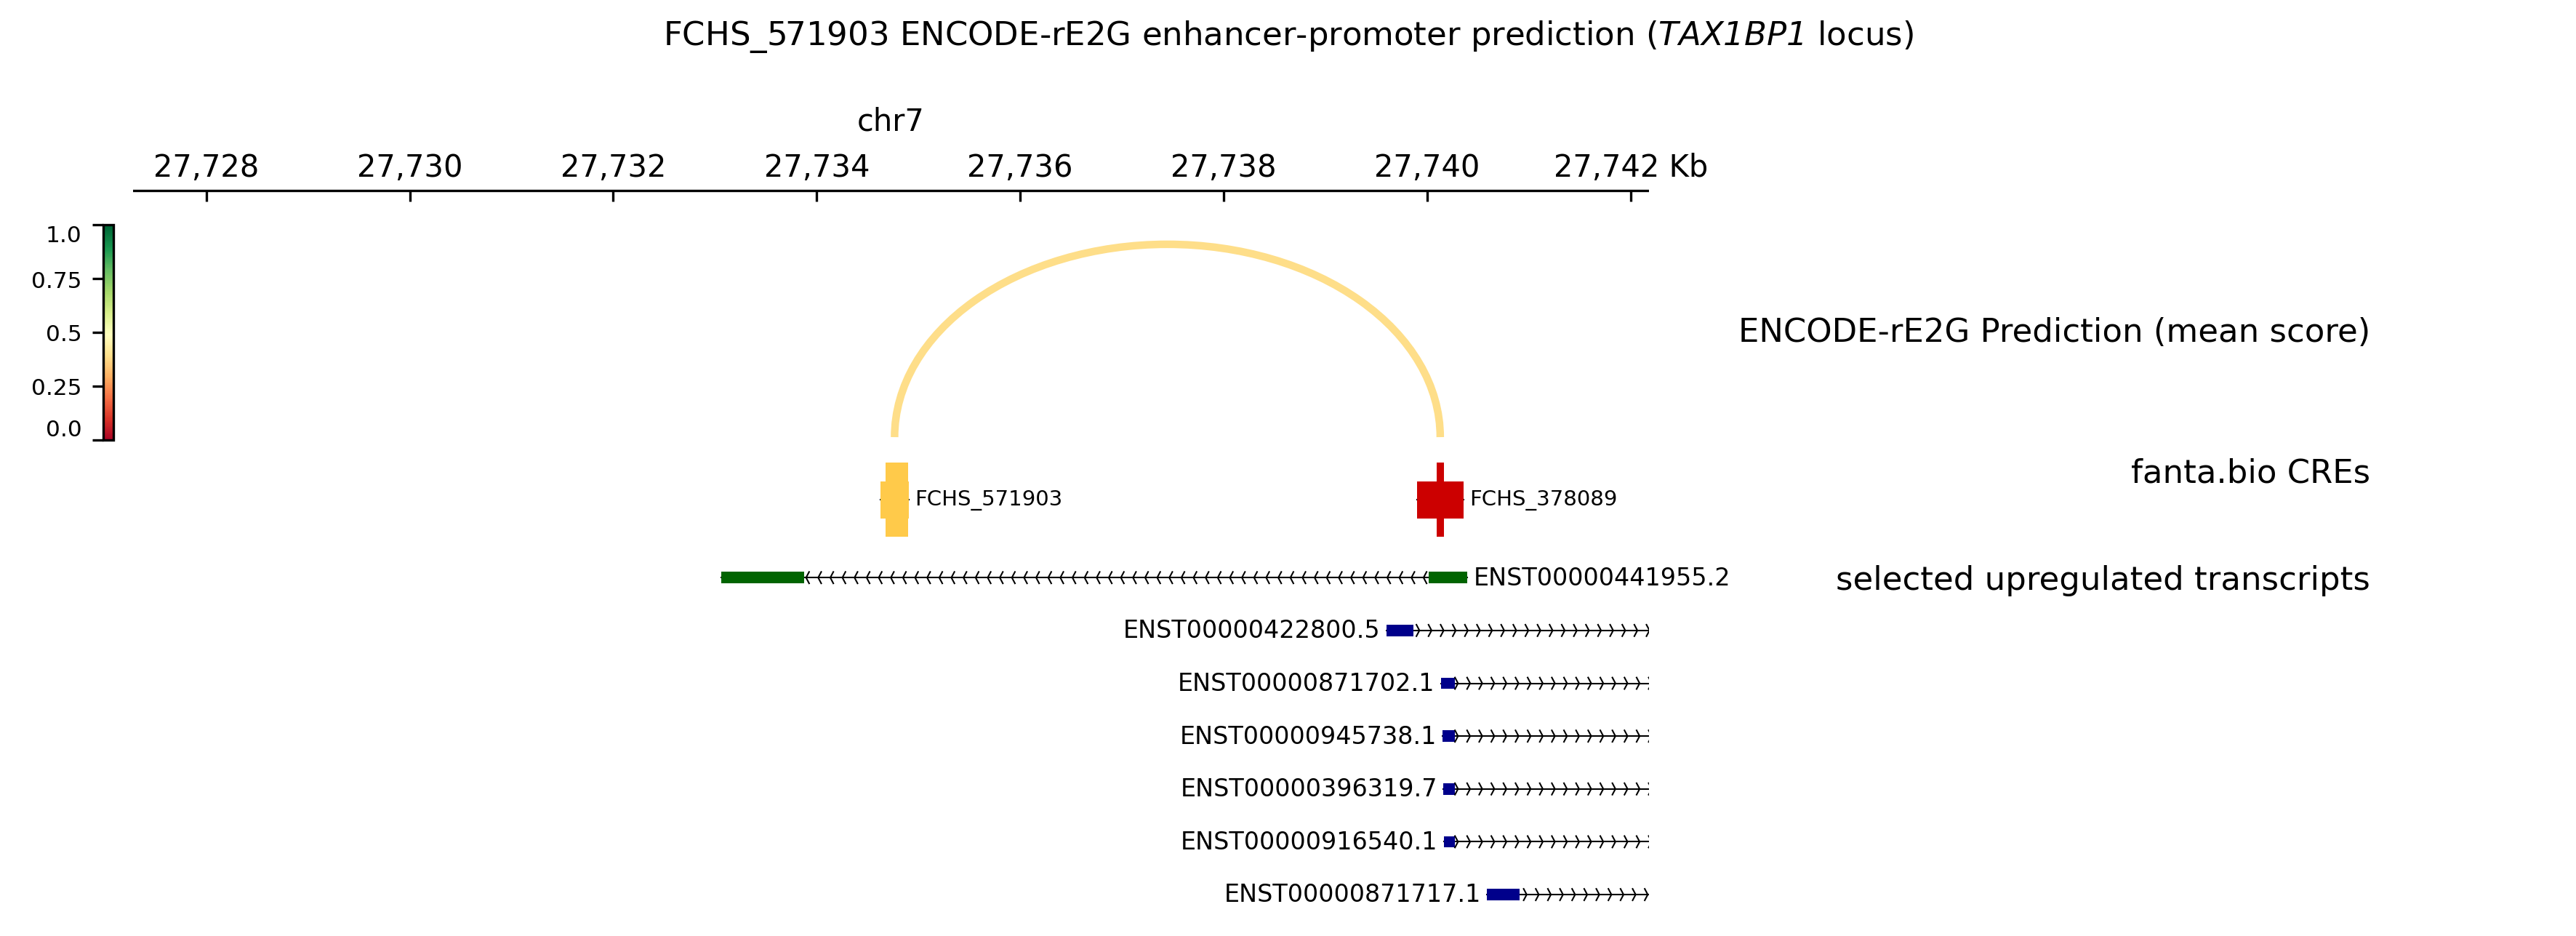

In [45]:
# Arcs on top, CRE anchors in the middle, up5p transcript models at the bottom.

fchs_ini = out_dir / "FCHS_571903_tracks.ini"
fchs_png = out_dir / "FCHS_571903_re2g_up5p.png"
fchs_ini.write_text(
    f"""\
[spacer]
height = 0.9

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[rE2G arcs]
file = {fchs_links.name}
title = ENCODE-rE2G Prediction (mean score)
file_type = links
links_type = arcs
use_middle = true
height = 2.5
color = RdYlGn
min_value = 0
max_value = 1
line_width = 2.5
line_style = solid
compact_arcs_level = 1

[spacer]
height = 0.2

[fanta CRE]
file = {fchs_cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 1.0
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[up5p transcripts]
file = {fchs_bed12.name}
title = selected upregulated transcripts
file_type = bed
height = 4
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 8
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for $\mathrm{TAX1BP1}$ to render fully italic in the title.
fchs_mplrc = out_dir / "matplotlibrc"
fchs_mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(fchs_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "300",
        "--trackLabelFraction",
        "0.32",
        # Wider label column so the longer track title stays clear of the
        # transcript id that spills into the margin (all_labels_inside skips it).
        # Right-align track titles for the same reason.
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(fchs_png),
        "--title",
        r"FCHS_571903 ENCODE-rE2G enhancer-promoter prediction ($\mathrm{TAX1BP1}$ locus)",
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(fchs_mplrc)},
)
display(Image(filename=str(fchs_png)))